<h1> DQN Library Comparison

What is the purpose of each file?

**custom_dqn_metrics.json:** Training settings and final metrics

**custom_dqn_arrays.npz:** Arrays containing rewards, step counts, loss, and evaluation results

**custom_dqn_best.pth:** Weights of the best-trained network

**02_dqn_library_comparison.ipynb:** Training and evaluation of a library-based DQN, and a comparison between the two models

Using JSON and NPZ is better than a simple TXT file; Because both the results remain readable and we load the arrays directly into this Notebook.

#### Installation and Review of Stable-Baselines3

In [5]:
%pip install stable-baselines3

Note: you may need to restart the kernel to use updated packages.


In [ ]:
print("Stable-Baselines3 version:", sb3.__version__)
print("DQN available:", hasattr(sb3, "DQN"))

Stable-Baselines3 version: 2.7.0
DQN available: True


In [12]:
import json
import numpy as np
from pathlib import Path
import stable_baselines3 as sb3
import gymnasium as gym
from stable_baselines3 import DQN
import torch
import matplotlib.pyplot as plt



<h3> Step 1: Loading our own DQN results

In [7]:
results_dir = Path("results")

# Load saved metrics
with open(
    results_dir / "custom_dqn_metrics.json",
    "r",
    encoding="utf-8"
) as file:
    custom_metrics = json.load(file)

# Load saved arrays
custom_data = np.load(
    results_dir / "custom_dqn_arrays.npz"
)

# Extract training and evaluation results
custom_rewards = custom_data["training_rewards"]
custom_steps = custom_data["training_steps"]
custom_losses = custom_data["training_losses"]

custom_eval_rewards = custom_data[
    "independent_eval_rewards"
]

# Calculate the actual training interaction budget
custom_total_timesteps = int(
    np.sum(custom_steps)
)

print("Algorithm:", custom_metrics["algorithm"])
print("Environment:", custom_metrics["environment"])

print("Training episodes:", len(custom_rewards))
print("Total training timesteps:", custom_total_timesteps)
print("Gradient updates:", len(custom_losses))

print(
    "Independent evaluation mean:",
    custom_eval_rewards.mean()
)

print(
    "Episodes reaching 500:",
    np.sum(custom_eval_rewards >= 500)
)

Algorithm: Custom DQN
Environment: CartPole-v1
Training episodes: 3000
Total training timesteps: 178646
Gradient updates: 178583
Independent evaluation mean: 459.65
Episodes reaching 500: 90


<h3> Step 3: DQN Library Tutorial

Training may take some time. The library-based model runs on the CPU, and its number of training steps is set to match the budget used for our own DQN implementation.

Note: While we have aligned the configurations, the two implementations are not necessarily identical in every internal detail. For this reason, in the README, we present this as a comparison between two implementations with similar budgets and configurations—rather than an experiment where only a single variable differs.

In [9]:
results_dir = Path("results")
results_dir.mkdir(parents=True, exist_ok=True)

custom_data = np.load(
    results_dir / "custom_dqn_arrays.npz"
)

custom_steps = custom_data["training_steps"]
custom_total_timesteps = int(custom_steps.sum())

print("Custom DQN training episodes:", len(custom_steps))
print("Custom DQN total timesteps:", custom_total_timesteps)

Custom DQN training episodes: 3000
Custom DQN total timesteps: 178646


In [10]:
# Use the same environment
library_env = gym.make("CartPole-v1")

# Decay epsilon over approximately 50,000 environment steps
exploration_fraction = min(
    1.0,
    50_000 / custom_total_timesteps
)

library_model = DQN(
    policy="MlpPolicy",
    env=library_env,

    learning_rate=1e-3,
    buffer_size=10_000,
    learning_starts=64,
    batch_size=64,

    gamma=0.99,
    tau=1.0,
    train_freq=1,
    gradient_steps=1,
    target_update_interval=500,

    exploration_initial_eps=1.0,
    exploration_final_eps=0.05,
    exploration_fraction=exploration_fraction,

    policy_kwargs={
        "net_arch": [128, 128],
        "activation_fn": torch.nn.ReLU
    },

    seed=123,
    verbose=1
)

print("Training timesteps:", custom_total_timesteps)
print("Exploration fraction:", exploration_fraction)

library_model.learn(
    total_timesteps=custom_total_timesteps,
    log_interval=10
)

library_model.save(
    str(results_dir / "library_dqn_cartpole")
)

print("Library DQN training completed.")
print("Model saved.")

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Training timesteps: 178646
Exploration fraction: 0.2798831208087503
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 21.2     |
|    ep_rew_mean      | 21.2     |
|    exploration_rate | 0.996    |
| time/               |          |
|    episodes         | 10       |
|    fps              | 331      |
|    time_elapsed     | 0        |
|    total_timesteps  | 212      |
| train/              |          |
|    learning_rate    | 0.001    |
|    loss             | 0.000173 |
|    n_updates        | 147      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 20.3     |
|    ep_rew_mean      | 20.3     |
|    exploration_rate | 0.992    |
| time/               |          |
|    episodes         | 20       |
|    fps              | 288      |
|    time_elapsed     | 1        

<h3> Step 4: Evaluation

Next, we evaluate both models using the same 100 independent seeds mentioned earlier:
- Custom DQN: Average reward of 459.65
- Library DQN: Yet to be measured.
- In both cases, actions are selected greedily—that is, without exploration.
- The weights for neither model are updated during evaluation.

In [11]:
results_dir = Path("results")

# Load trained model
library_model = DQN.load(
    str(results_dir / "library_dqn_cartpole")
)

eval_env = gym.make("CartPole-v1")

# IMPORTANT: Use the exact same seeds as Custom DQN evaluation.
# If Custom DQN used seeds 0 to 99, keep this line unchanged.
eval_seeds = np.arange(100)

library_rewards = []
library_lengths = []

for seed in eval_seeds:
    obs, info = eval_env.reset(seed=int(seed))

    total_reward = 0
    episode_length = 0
    done = False

    while not done:
        action, _ = library_model.predict(
            obs,
            deterministic=True
        )

        obs, reward, terminated, truncated, info = (
            eval_env.step(int(action))
        )

        total_reward += reward
        episode_length += 1
        done = terminated or truncated

    library_rewards.append(total_reward)
    library_lengths.append(episode_length)

eval_env.close()

library_rewards = np.asarray(library_rewards)
library_lengths = np.asarray(library_lengths)

np.savez(
    results_dir / "library_dqn_eval.npz",
    seeds=eval_seeds,
    rewards=library_rewards,
    lengths=library_lengths
)

print("Library DQN Evaluation")
print("----------------------")
print(f"Episodes: {len(library_rewards)}")
print(f"Mean reward: {library_rewards.mean():.2f}")
print(f"Std reward:  {library_rewards.std():.2f}")
print(f"Median:      {np.median(library_rewards):.2f}")
print(f"Min reward:  {library_rewards.min():.2f}")
print(f"Max reward:  {library_rewards.max():.2f}")
print(f"Mean length: {library_lengths.mean():.2f}")

custom_mean = 459.65
library_mean = library_rewards.mean()

print("\nComparison")
print(f"Custom DQN:  {custom_mean:.2f}")
print(f"Library DQN: {library_mean:.2f}")
print(f"Difference:  {library_mean - custom_mean:+.2f}")

Library DQN Evaluation
----------------------
Episodes: 100
Mean reward: 111.14
Std reward:  7.45
Median:      111.00
Min reward:  98.00
Max reward:  126.00
Mean length: 111.14

Comparison
Custom DQN:  459.65
Library DQN: 111.14
Difference:  -348.51


The current results indicate that the custom DQN performs significantly better than the library-based DQN. However, the library-based model has not yet reached the desired level of performance, and we need to investigate the reason for this.

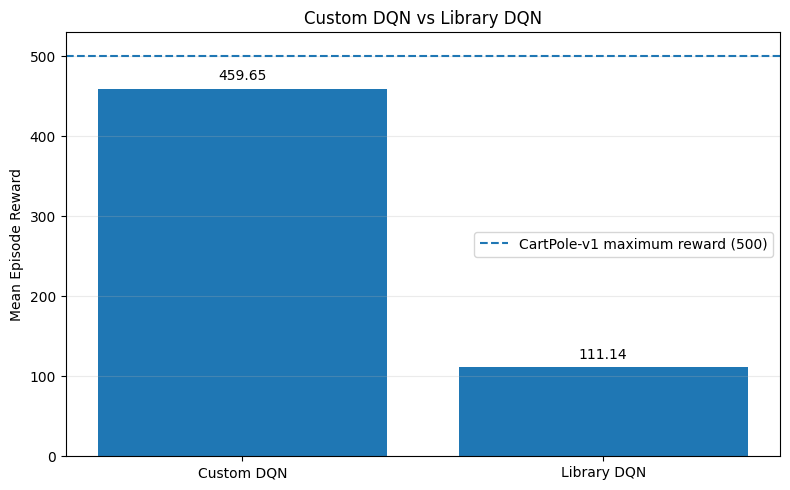

In [13]:
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

models = ["Custom DQN", "Library DQN"]
mean_rewards = [459.65, 111.14]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(models, mean_rewards)

ax.axhline(
    y=500,
    linestyle="--",
    label="CartPole-v1 maximum reward (500)"
)

ax.bar_label(bars, fmt="%.2f", padding=4)

ax.set_ylabel("Mean Episode Reward")
ax.set_title("Custom DQN vs Library DQN")
ax.set_ylim(0, 530)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    results_dir / "dqn_mean_reward_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

At the end of training, the moving average reward was only 129. Therefore, the evaluation result of 111.14 is consistent with the training trend, and for now, there is no evidence to suggest that the issue lies with the evaluation.